In [1]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [2]:
import json
def load_jsonl(path):
    data = {'en': [], 'de': []}
    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()
        for line in lines:
            d = json.loads(line)
            data['en'].append(d['en'])
            data['de'].append(d['de'])
    return data
train_df = pd.DataFrame(load_jsonl("train.jsonl"))
val_df = pd.DataFrame(load_jsonl("val.jsonl"))
test_df = pd.DataFrame(load_jsonl("test.jsonl"))

In [3]:
train_df.head()

,en,de
0,"Two young, White males are outside near many b...",Zwei junge weiße Männer sind im Freien in der ...
1,Several men in hard hats are operating a giant...,Mehrere Männer mit Schutzhelmen bedienen ein A...
2,A little girl climbing into a wooden playhouse.,Ein kleines Mädchen klettert in ein Spielhaus ...
3,A man in a blue shirt is standing on a ladder ...,Ein Mann in einem blauen Hemd steht auf einer ...
4,Two men are at the stove preparing food.,Zwei Männer stehen am Herd und bereiten Essen zu.


In [4]:
print(len(train_df), len(val_df), len(test_df))

29000 1014 1000


In [5]:
from collections import Counter
def preprocess(text):
    text = text.lower()
    return text.split()
MAX_LEN = 32
PAD_IDX = 0 
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3
class Vocab:
    def __init__(self, texts):
        c = Counter()
        for t in texts:
            c.update(preprocess(t))
        self.word2idx = {"<pad>": PAD_IDX, "<sos>": SOS_IDX, "<eos>": EOS_IDX, "<unk>": UNK_IDX}
        count = len(self.word2idx)
        self.idx2word = {PAD_IDX: "<pad>", SOS_IDX: "<sos>", EOS_IDX: "<eos>", UNK_IDX: "<unk>"}
        for word, _ in sorted(c.items(), key=lambda item: (-item[1], item[0])):
            self.word2idx[word] = count
            self.idx2word[count] = word
            count += 1
    def __len__(self):
        return len(self.word2idx)
    def encode(self, text):
        return [self.word2idx.get(t, UNK_IDX) for t in preprocess(text)]
    def decode(self, ids):
        out = []
        for i in ids:
            tok = self.idx2word[int(i)]
            if tok == "<eos>":
                break
            if tok not in ("<pad>", "<sos>"):
                out.append(tok)
        return " ".join(out)

In [6]:
src_vocab = Vocab(train_df['en'].values)
tgt_vocab = Vocab(train_df['de'].values)

In [7]:
print(len(src_vocab), len(tgt_vocab))

14450 24333


In [8]:
text = "A large crowd"
src_vocab.encode(text)[:5]

[4, 53, 96]

In [9]:
x = [13, 2102,   42,   56,   10,    6,   75,  812,  109,    5,    6,
         2039,    5,    6,  804,  481,   76]
y = [1] + x + [2]
c = len(y)
y = y + [0] * (32 - c)
print(len(y))

32


In [10]:
class TranlationDataset(torch.utils.data.Dataset):
    def __init__(self, frame, src_vocab, tgt_vocab):
        # print("init")
        self.frame = frame.reset_index(drop=True)
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab
    def __len__(self):
        # print("len")
        return len(self.frame)
    def __getitem__(self, index):
        # print("getitem")
        r = self.frame.iloc[index]
        src_list = [self.src_vocab.word2idx["<sos>"]] + self.src_vocab.encode(r['en'])[:MAX_LEN-2] + [self.src_vocab.word2idx["<eos>"]]
        # src_len = len(src_list)
        # src_list += [self.src_vocab.word2idx["<pad>"]] * (MAX_LEN - src_len)
        src = torch.tensor(
            src_list,
            dtype=torch.long
        )
        tgt_list = [self.tgt_vocab.word2idx["<sos>"]] + self.tgt_vocab.encode(r['de'])[:MAX_LEN-2] + [self.tgt_vocab.word2idx["<eos>"]]
        # tgt_len = len(tgt_list)
        # tgt_list += [self.tgt_vocab.word2idx["<pad>"]] * (MAX_LEN - tgt_len)
        tgt = torch.tensor(
            tgt_list,
            dtype=torch.long
        )
        # print(src)
        # print(tgt)
        return src, tgt

In [11]:
from torch.nn.utils.rnn import pad_sequence
def collate_fn(batch):
    # print("collate fn")
    srcs, tgts = zip(*batch)
    lens = torch.tensor([len(x) for x in srcs], dtype=torch.long)
    # print(lens)
    order = torch.argsort(lens, descending=True)
    # print(order)
    lens = lens[order]
    srcs = [srcs[i] for i in order]
    tgts = [tgts[i] for i in order]
    src = pad_sequence(srcs, batch_first=True, padding_value=PAD_IDX)
    tgt = pad_sequence(tgts, batch_first=True, padding_value=PAD_IDX)
    # if we want to pad to a fixed global max length
    # if src.size(1) < MAX_LEN:
    #     pad_size = MAX_LEN - src.size(1)
    #     src = nn.functional.pad(src, (0, pad_size), value=PAD_IDX)
    #     tgt = nn.functional.pad(tgt, (0, pad_size), value=PAD_IDX)
    return src, lens, tgt


In [12]:
BATCH_SIZE = 64
train_loader = torch.utils.data.DataLoader(TranlationDataset(train_df, src_vocab, tgt_vocab), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = torch.utils.data.DataLoader(TranlationDataset(val_df, src_vocab, tgt_vocab), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=0, pin_memory=torch.cuda.is_available())

In [13]:
x, l, y = next(iter(train_loader))
print(x.shape, l[:5].tolist(), y.shape)

torch.Size([64, 27]) [27, 24, 24, 23, 23] torch.Size([64, 29])


In [14]:
x

tensor([[   1,  146,   14,  ...,    6,  587,    2],
        [   1,    4,   57,  ...,    0,    0,    0],
        [   1,    4,  463,  ...,    0,    0,    0],
        ...,
        [   1,    4,   14,  ...,    0,    0,    0],
        [   1,  210,   15,  ...,    0,    0,    0],
        [   1,    8, 1100,  ...,    0,    0,    0]])

In [15]:
y

tensor([[    1,     7,   253,  ...,  4506,   314,     2],
        [    1,     4, 14092,  ...,     0,     0,     0],
        [    1,     4,    11,  ...,     0,     0,     0],
        ...,
        [    1,     7,   141,  ...,     0,     0,     0],
        [    1,    85,   103,  ...,     0,     0,     0],
        [    1,     4,    11,  ...,     0,     0,     0]])

In [16]:
import math
"""
Encoder self-attention: Q=K=V=encoder
Decoder self-attention: Q=K=V=decoder
Decoder cross-attention: Q=decoder, K=V=encoder

Mask convention:
    True  -> attention is allowed
    False -> attention is masked
"""

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v, mask=None):
        b = q.size(0)

        q = self.q_proj(q)
        k = self.k_proj(k)
        v = self.v_proj(v)

        q = q.view(b, -1, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(b, -1, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(b, -1, self.num_heads, self.head_dim).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1))
        scores = scores / math.sqrt(self.head_dim)

        if mask is not None:
            # mask must broadcast to (B, H, Sq, Sk)
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

        attention = torch.softmax(scores, dim=-1)
        attention = self.dropout(attention)

        result = torch.matmul(attention, v)
        result = result.transpose(1, 2).contiguous()
        result = result.view(b, -1, self.d_model)

        return self.out_proj(result)


class SinosoidalPosEmb(nn.Module):
    def __init__(self, d_model, max_len=MAX_LEN):
        super().__init__()

        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * -(math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)

    def forward(self, emb):
        return self.pe[:, :emb.size(1)]


class EncoderBlock(nn.Module):
    def __init__(self, d_model=256, num_heads=8, d_ff=1024, dropout=0.1):
        super().__init__()

        self.mha = MultiHeadAttention(d_model, num_heads, dropout)

        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )

        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Pre-norm is generally easier to optimize for deeper transformers.
        x = x + self.dropout(self.mha(self.ln1(x), self.ln1(x), self.ln1(x), mask))
        x = x + self.dropout(self.ff(self.ln2(x)))
        return x


class Encoder(nn.Module):
    def __init__(
        self,
        input_dim,
        d_model=256,
        num_heads=8,
        d_ff=1024,
        n_enc=4,
        dropout=0.1
    ):
        super().__init__()

        self.d_model = d_model
        self.emb = nn.Embedding(input_dim, d_model, padding_idx=PAD_IDX)
        self.pe = SinosoidalPosEmb(d_model, MAX_LEN)

        self.layers = nn.ModuleList([
            EncoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(n_enc)
        ])

        self.dropout = nn.Dropout(dropout)
        self.final_ln = nn.LayerNorm(d_model)

    def forward(self, src, mask=None):
        x = self.emb(src) * math.sqrt(self.d_model)
        x = self.dropout(x + self.pe(x))

        for layer in self.layers:
            x = layer(x, mask)

        return self.final_ln(x)


class DecoderBlock(nn.Module):
    def __init__(self, d_model=256, num_heads=8, d_ff=1024, dropout=0.1):
        super().__init__()

        self.self_mha = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_mha = MultiHeadAttention(d_model, num_heads, dropout)

        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )

        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)
        self.ln3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_out, self_mask=None, src_mask=None):
        y = self.ln1(x)
        x = x + self.dropout(self.self_mha(y, y, y, self_mask))

        y = self.ln2(x)
        x = x + self.dropout(self.cross_mha(y, enc_out, enc_out, src_mask))

        y = self.ln3(x)
        x = x + self.dropout(self.ff(y))

        return x


class Decoder(nn.Module):
    def __init__(
        self,
        output_dim,
        d_model=256,
        num_heads=8,
        d_ff=1024,
        n_dec=4,
        dropout=0.1
    ):
        super().__init__()

        self.output_dim = output_dim
        self.d_model = d_model

        self.emb = nn.Embedding(output_dim, d_model, padding_idx=PAD_IDX)
        self.pe = SinosoidalPosEmb(d_model, MAX_LEN)

        self.layers = nn.ModuleList([
            DecoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(n_dec)
        ])

        self.final_ln = nn.LayerNorm(d_model)
        self.fc_out = nn.Linear(d_model, output_dim, bias=False)
        self.dropout = nn.Dropout(dropout)

        # Weight tying gives the decoder a stronger and more parameter-efficient
        # target-token representation.
        self.fc_out.weight = self.emb.weight

    def forward(self, tgt, enc_out, self_mask=None, src_key_padding_mask=None):
        x = self.emb(tgt) * math.sqrt(self.d_model)
        x = self.dropout(x + self.pe(x))

        for layer in self.layers:
            x = layer(x, enc_out, self_mask, src_key_padding_mask)

        x = self.final_ln(x)
        return self.fc_out(x)


class TransformerModel(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    @staticmethod
    def src_attention_mask(src):
        # (B, 1, 1, S): True only for real source tokens.
        return (src != PAD_IDX).unsqueeze(1).unsqueeze(1)

    @staticmethod
    def tgt_attention_mask(tgt):
        b, t = tgt.shape
        device = tgt.device

        # Causal mask: a target position may not see future positions.
        causal = torch.tril(
            torch.ones(t, t, dtype=torch.bool, device=device)
        ).unsqueeze(0).unsqueeze(0)

        # Target padding must never be used as a key.
        tgt_keep = (tgt != PAD_IDX).unsqueeze(1).unsqueeze(1)

        # (B, 1, T, T)
        return causal & tgt_keep

    def encode(self, src):
        src_mask = self.src_attention_mask(src)
        return self.encoder(src, src_mask)

    def forward(self, src, lengths, tgt):
        # `tgt` is the decoder INPUT sequence.
        # During training this must be tgt[:, :-1], while the loss is
        # computed against tgt[:, 1:]. During autoregressive inference,
        # `tgt` contains only the tokens generated so far.
        del lengths  # kept for API compatibility with the existing notebook

        enc_out = self.encode(src)
        src_mask = self.src_attention_mask(src)
        tgt_mask = self.tgt_attention_mask(tgt)

        return self.decoder(tgt, enc_out, tgt_mask, src_mask)


# Xavier initialization for the newly defined linear layers.
def initialize_transformer_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Embedding):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if module.padding_idx is not None:
            with torch.no_grad():
                module.weight[module.padding_idx].zero_()


In [17]:
encoder = Encoder(input_dim=len(src_vocab))
decoder = Decoder(output_dim=len(tgt_vocab))
model = TransformerModel(encoder, decoder)
for src, lengths, tgt in train_loader:
    model(src, lengths, tgt)
    break

In [18]:
from tqdm import tqdm

def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total = torch.zeros(1, device=DEVICE)

    for src, lengths, tgt in tqdm(loader, desc="Calculating train loss..."):
        src = src.to(DEVICE, non_blocking=True)
        lengths = lengths.to(DEVICE, non_blocking=True)
        tgt = tgt.to(DEVICE, non_blocking=True)

        # CRITICAL:
        # Decoder input = <sos> y1 y2 ... y(n-1)
        # Target        = y1   y2 ... yn <eos>
        #
        # Feeding the full target and comparing out[:, 1:] with
        # tgt[:, 1:] leaks the answer into the decoder during training.
        tgt_in = tgt[:, :-1]
        tgt_out = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)

        out = model(src, lengths, tgt_in)

        loss = criterion(
            out.reshape(-1, out.size(-1)),
            tgt_out.reshape(-1)
        )

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total += loss.detach()

    return (total / max(len(loader), 1)).item()


@torch.no_grad()
def eval_epoch(model, loader, criterion):
    model.eval()
    total = torch.zeros(1, device=DEVICE)

    for src, lengths, tgt in tqdm(loader, desc="Calculating val loss..."):
        src = src.to(DEVICE, non_blocking=True)
        lengths = lengths.to(DEVICE, non_blocking=True)
        tgt = tgt.to(DEVICE, non_blocking=True)

        tgt_in = tgt[:, :-1]
        tgt_out = tgt[:, 1:]

        out = model(src, lengths, tgt_in)

        loss = criterion(
            out.reshape(-1, out.size(-1)),
            tgt_out.reshape(-1)
        )

        total += loss.detach()

    return (total / max(len(loader), 1)).item()


In [19]:
# Teacher-forcing sanity check
#
# During training, position t receives tokens only up to y_{t-1}
# and must predict y_t. At inference, this is exactly what happens.

src0, lengths0, tgt0 = next(iter(train_loader))
print("Full target shape:   ", tuple(tgt0.shape))
print("Decoder input shape: ", tuple(tgt0[:, :-1].shape))
print("Prediction shape:    ", tuple(tgt0[:, 1:].shape))
print("Shifted-target training is enabled.")


Full target shape:    (64, 25)
Decoder input shape:  (64, 24)
Prediction shape:     (64, 24)
Shifted-target training is enabled.


Calculating val loss...: 100%|██████████| 16/16 [00:00<00:00, 47.39it/s]


Epoch 01 | train_loss=6.1102 | val_loss=5.1276 | lr=3.00e-04
  -> best checkpoint saved (5.1276)


Calculating val loss...: 100%|██████████| 16/16 [00:00<00:00, 41.77it/s]


Epoch 02 | train_loss=4.7837 | val_loss=4.4544 | lr=3.00e-04
  -> best checkpoint saved (4.4544)


Calculating val loss...: 100%|██████████| 16/16 [00:00<00:00, 52.37it/s]


...

Epoch 24 | train_loss=2.1806 | val_loss=3.3300 | lr=7.50e-05


Calculating val loss...: 100%|██████████| 16/16 [00:00<00:00, 69.48it/s]


Epoch 25 | train_loss=2.1682 | val_loss=3.3367 | lr=7.50e-05


Calculating val loss...: 100%|██████████| 16/16 [00:00<00:00, 68.59it/s]


Epoch 26 | train_loss=2.1586 | val_loss=3.3373 | lr=3.75e-05
Early stopping.


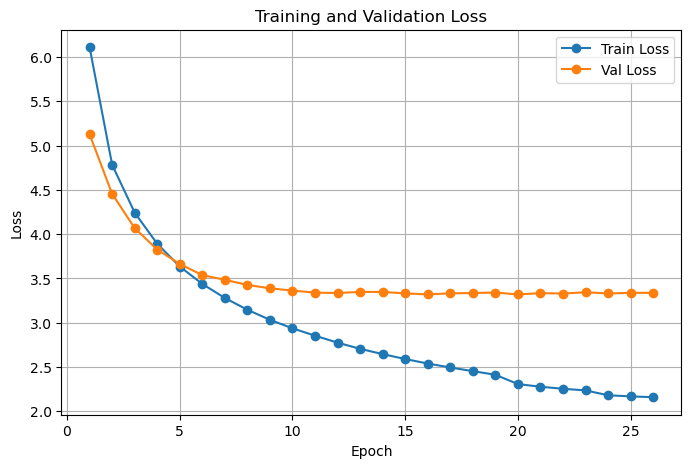

In [20]:
import matplotlib.pyplot as plt

model = TransformerModel(
    Encoder(len(src_vocab)),
    Decoder(len(tgt_vocab))
).to(DEVICE)

model.apply(initialize_transformer_weights)

# A slightly larger LR with AdamW works better for this transformer than
# the original 1e-4 Adam setup.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    betas=(0.9, 0.98),
    eps=1e-9,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX,
    label_smoothing=0.1
)

# Reduce LR once validation loss plateaus.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

train_losses = []
val_losses = []

CKPT_PATH = "best_model.pt"
best_val_loss = float("inf")
patience = 6
epochs_without_improvement = 0
NUM_EPOCHS = 30

for epoch in range(NUM_EPOCHS):
    train_loss = train_epoch(model, train_loader, optimizer, criterion)
    val_loss = eval_epoch(model, val_loader, criterion)
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch + 1:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"lr={current_lr:.2e}"
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "val_loss": val_loss,
        }, CKPT_PATH)

        print(f"  -> best checkpoint saved ({best_val_loss:.4f})")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train Loss", marker="o")
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Val Loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [21]:
checkpoint = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

if "optimizer_state_dict" in checkpoint:
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
if "scheduler_state_dict" in checkpoint:
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

print(
    f"Loaded model from epoch {checkpoint['epoch']} "
    f"with val_loss {checkpoint['val_loss']:.4f}"
)


Loaded model from epoch 20 with val_loss 3.3188


In [22]:
# Useful diagnostics: these often reveal whether poor BLEU is caused by
# truncation or excessive unknown tokens rather than the Transformer itself.

def avg_token_length(frame, column):
    vals = [len(preprocess(x)) for x in frame[column]]
    return float(np.mean(vals))

print(f"Average source tokens: {avg_token_length(train_df, 'en'):.2f}")
print(f"Average target tokens: {avg_token_length(train_df, 'de'):.2f}")
print(f"MAX_LEN: {MAX_LEN}")

src_trunc = sum(len(preprocess(x)) >= MAX_LEN - 2 for x in test_df["en"])
tgt_trunc = sum(len(preprocess(x)) >= MAX_LEN - 2 for x in test_df["de"])

print(f"Test source examples truncated: {src_trunc}/{len(test_df)}")
print(f"Test target examples truncated: {tgt_trunc}/{len(test_df)}")


Average source tokens: 11.90
Average target tokens: 11.12
MAX_LEN: 32
Test source examples truncated: 2/1000
Test target examples truncated: 1/1000


In [23]:
import torch.nn.functional as F

def make_src_padding_mask(src):
    """(B, 1, 1, S), True = real source token."""
    return (src != PAD_IDX).unsqueeze(1).unsqueeze(1)


def make_causal_mask(tgt_len, device):
    """(1, 1, T, T), True = past/current positions are visible."""
    return torch.tril(
        torch.ones(tgt_len, tgt_len, dtype=torch.bool, device=device)
    ).unsqueeze(0).unsqueeze(0)


@torch.no_grad()
def beam_search_decode(
    model,
    src,
    src_vocab,
    tgt_vocab,
    beam_width=5,
    max_len=MAX_LEN,
    length_penalty_alpha=0.6,
    device=DEVICE
):
    """
    Beam search for a SINGLE source sentence.

    Uses:
      - the same source-padding mask as training;
      - length normalization to avoid excessively short translations;
      - beam width 5 for better search than greedy/beam-3 decoding.
    """
    del src_vocab, tgt_vocab  # kept in signature for notebook compatibility

    model.eval()
    src = src.to(device)

    src_mask = make_src_padding_mask(src)
    enc_out = model.encoder(src, src_mask)

    beams = [([SOS_IDX], 0.0, False)]

    def normalized_score(score, tokens):
        # Exclude SOS from the effective translation length.
        length = max(len(tokens) - 1, 1)
        penalty = ((5.0 + length) ** length_penalty_alpha) / (6.0 ** length_penalty_alpha)
        return score / penalty

    for _ in range(max_len - 1):
        candidates = []

        if all(finished for _, _, finished in beams):
            break

        for tokens, score, finished in beams:
            if finished:
                candidates.append((tokens, score, True))
                continue

            tgt = torch.tensor([tokens], dtype=torch.long, device=device)
            tgt_mask = model.tgt_attention_mask(tgt)

            logits = model.decoder(
                tgt,
                enc_out,
                tgt_mask,
                src_mask
            )

            log_probs = F.log_softmax(logits[0, -1], dim=-1)

            # Keep search efficient while still exploring several candidates.
            k = min(beam_width * 2, log_probs.numel())
            top_log_probs, top_ids = torch.topk(log_probs, k=k)

            for lp, idx in zip(top_log_probs.tolist(), top_ids.tolist()):
                new_tokens = tokens + [idx]
                new_score = score + lp
                new_finished = (idx == EOS_IDX)
                candidates.append((new_tokens, new_score, new_finished))

        candidates.sort(
            key=lambda item: normalized_score(item[1], item[0]),
            reverse=True
        )
        beams = candidates[:beam_width]

    beams.sort(
        key=lambda item: normalized_score(item[1], item[0]),
        reverse=True
    )

    return [
        (tokens, normalized_score(score, tokens))
        for tokens, score, _ in beams
    ]


In [24]:
def ids_to_sentence(ids, vocab):
    """Convert a list/tensor of token ids to a human-readable string using vocab.decode."""
    return vocab.decode(ids)

# pick a training example
example_idx = 0
example_row = train_df.iloc[example_idx]
src_text = example_row['en']
ref_text = example_row['de']

src_ids = [SOS_IDX] + src_vocab.encode(src_text)[:MAX_LEN - 2] + [EOS_IDX]
src_tensor = torch.tensor([src_ids], dtype=torch.long)

beams = beam_search_decode(model, src_tensor, src_vocab, tgt_vocab,
                            beam_width=5, max_len=MAX_LEN, length_penalty_alpha=0.6)

print(f"Source (en):    {src_text}")
print(f"Reference (de): {ref_text}\n")
print("Top beams:")
for rank, (tokens, score) in enumerate(beams, start=1):
    sentence = ids_to_sentence(tokens, tgt_vocab)
    print(f"  {rank}. score={score:.4f}  ->  {sentence}")

Source (en):    Two young, White males are outside near many bushes.
Reference (de): Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.

Top beams:
  1. score=-1.2621  ->  zwei junge weiße männer sind im freien in der nähe von vielen büschen.
  2. score=-1.4142  ->  zwei junge weiße männer sind draußen in der nähe von vielen büschen.
  3. score=-1.8366  ->  zwei junge, weiße männer sind im freien in der nähe von vielen büschen.
  4. score=-2.0417  ->  zwei junge, weiße männer sind draußen in der nähe von vielen büschen.
  5. score=-2.4760  ->  zwei junge weiße männer sind im freien bei vielen büschen.


In [25]:
from collections import Counter

def get_ngrams(tokens, n):
    """Return a Counter of n-grams (as tuples) from a token list."""
    return Counter(tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1))

def corpus_bleu_score(references, hypotheses, max_n=4, smooth_eps=1e-9):
    """
    references: list[list[str]]  - one reference token list per example
    hypotheses: list[list[str]]  - one hypothesis token list per example
    Computes corpus-level BLEU-max_n with additive (epsilon) smoothing on n-gram precision,
    and standard brevity penalty.
    """
    precisions = []
    for n in range(1, max_n + 1):
        match_count = 0
        total_count = 0
        for ref, hyp in zip(references, hypotheses):
            ref_ngrams = get_ngrams(ref, n)
            hyp_ngrams = get_ngrams(hyp, n)
            overlap = hyp_ngrams & ref_ngrams  # min counts per ngram
            match_count += sum(overlap.values())
            total_count += max(sum(hyp_ngrams.values()), 0)
        # smoothed precision to avoid zero when match_count == 0
        precision = (match_count + smooth_eps) / (total_count + smooth_eps)
        precisions.append(precision)

    # geometric mean of n-gram precisions
    log_precision_sum = sum(math.log(p) for p in precisions) / max_n
    geo_mean = math.exp(log_precision_sum)

    ref_len = sum(len(r) for r in references)
    hyp_len = sum(len(h) for h in hypotheses)
    if hyp_len == 0:
        brevity_penalty = 0.0
    elif hyp_len > ref_len:
        brevity_penalty = 1.0
    else:
        brevity_penalty = math.exp(1 - ref_len / max(hyp_len, 1))

    bleu = brevity_penalty * geo_mean
    return bleu * 100  # as percentage

# --- Evaluate over a test subset ---
N_EVAL = 100  # subset size (k)
eval_df = test_df.iloc[:N_EVAL]

references = []
hypotheses = []

for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    src_text, ref_text = row['en'], row['de']
    src_ids = [SOS_IDX] + src_vocab.encode(src_text)[:MAX_LEN - 2] + [EOS_IDX]
    src_tensor = torch.tensor([src_ids], dtype=torch.long)

    beams = beam_search_decode(model, src_tensor, src_vocab, tgt_vocab,
                                beam_width=5, max_len=MAX_LEN, length_penalty_alpha=0.6)
    best_tokens, _ = beams[0]

    hyp_sentence = ids_to_sentence(best_tokens, tgt_vocab)
    references.append(preprocess(ref_text))     # reuse the notebook's own tokenizer
    hypotheses.append(hyp_sentence.split())

bleu = corpus_bleu_score(references, hypotheses, max_n=4)
print(f"Corpus BLEU on {N_EVAL} test examples: {bleu:.2f}")

100%|██████████| 100/100 [00:35<00:00,  2.81it/s]

Corpus BLEU on 100 test examples: 31.71


In [26]:
N_QUAL = 5
qual_df = test_df.iloc[:N_QUAL]

for i, row in qual_df.iterrows():
    src_text, ref_text = row['en'], row['de']
    src_ids = [SOS_IDX] + src_vocab.encode(src_text)[:MAX_LEN - 2] + [EOS_IDX]
    src_tensor = torch.tensor([src_ids], dtype=torch.long)

    beams = beam_search_decode(model, src_tensor, src_vocab, tgt_vocab,
                                beam_width=5, max_len=MAX_LEN, length_penalty_alpha=0.6)

    print(f"Example {i}")
    print(f"  Source:      {src_text}")
    print(f"  Reference:   {ref_text}")
    print("  Top predictions:")
    for rank, (tokens, score) in enumerate(beams, start=1):
        pred_sentence = ids_to_sentence(tokens, tgt_vocab)
        print(f"    {rank}. (score={score:.4f}) {pred_sentence}")
    print()

Example 0
  Source:      A man in an orange hat starring at something.
  Reference:   Ein Mann mit einem orangefarbenen Hut, der etwas anstarrt.
  Top predictions:
    1. (score=-1.1313) ein mann mit einem orangefarbenen hut starrt auf etwas.
    2. (score=-1.6834) ein mann mit orangefarbenem hut starrt auf etwas.
    3. (score=-2.0195) ein mann in einem orangefarbenen hut starrt auf etwas.
    4. (score=-2.3874) ein mann mit orangefarbener kopfbedeckung starrt auf etwas.
    5. (score=-2.7230) ein mann mit einem orangefarbenen hut starrt auf etwas an.

Example 1
  Source:      A Boston Terrier is running on lush green grass in front of a white fence.
  Reference:   Ein Boston Terrier läuft über saftig-grünes Gras vor einem weißen Zaun.
  Top predictions:
    1. (score=-5.1613) ein windsurfer läuft vor einem weißen zaun auf grünem gras vor einem weißen zaun.
    2. (score=-5.2302) ein windsurfer läuft vor einem weißen zaun auf grünem gras.
    3. (score=-6.2686) ein windsurfer läuft vo